# Procesamiento de Aforos Vehiculares Empíricos

Extracción y procesamiento de tasas de flujo vehicular y distribución por tipo de vehículo desde registros de video en intersección crítica.

## Fuente de Datos

La Tabla 13 de la tesis de Sarango aporta los conteos manuales usados en este análisis.

**Instrumento:** [Cámara Sony IMX766 y Dron DJI Phantom 4 Pro V2.0]

**Ubicación:** [Avenida Isidro Ayora y la Avenida 8 de Diciembre]

**Fecha/Hora videos:** [13 de enero de 2025]

![Tabla 13 - Registro de aforos vehiculares](./imagen_tabla_13.png)

In [5]:
import os
from dotenv import load_dotenv
load_dotenv()

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import glob

## Datos de Flujo Vehicular

Se transcriben únicamente los conteos manuales de la Tabla 13 de Sarango (2025). Las tasas se calculan con el conteo manual y la duración de cada muestra; no se mezclan con detecciones YOLOv5.

Referencia:
- Tesis: "Analisis de trafico vehicular en interseccion critica"
- Autor: E. Sarango (2025)
- Ubicacion: Av. Isidro Ayora y Av. 8 de Diciembre, Loja
- Instrumento: Camara Sony IMX766 y Dron DJI Phantom 4 Pro
- Fecha: 13 de enero de 2025

Variables:
- Muestra_Video: identificador del video de analisis
- Vehiculos_Detectados: conteo manual total de vehículos en el video
- Tiempo_segundos: duracion del video en segundos
- Flujo_veh_seg: tasa de flujo en vehiculos/segundo
- Flujo_veh_min: tasa de flujo en vehiculos/minuto
- Tasa_Flujo_veh_h: tasa de flujo en vehiculos/hora (calculada)

In [ ]:
data = {
    'Muestra_Video': ['ANALISIS_1', 'ANALISIS_2', 'ANALISIS_3', 'ANALISIS_4', 'ANALISIS_5', 'ANALISIS_6', 'ANALISIS_7'],
    'Vehiculos_Detectados': [135, 60, 33, 116, 120, 132, 38],  # Conteos manuales de la Tabla 13
    'Tiempo_segundos': [410, 192, 92, 330, 344, 410, 119],
}

df = pd.DataFrame(data)
df['Flujo_veh_seg'] = df['Vehiculos_Detectados'] / df['Tiempo_segundos']
df['Flujo_veh_min'] = df['Flujo_veh_seg'] * 60
df['Tasa_Flujo_veh_h'] = df['Flujo_veh_seg'] * 3600

## Distribución Vehicular por Tipo

Conteo de vehículos clasificados por tipo a partir de las etiquetas del dataset.

In [7]:
# API key debe estar en variable de entorno ROBOFLOW_API_KEY
from roboflow import Roboflow
rf = Roboflow(api_key=os.getenv("ROBOFLOW_API_KEY"))
project = rf.workspace("bd20244-cy0u2").project("bd_2024_4-vxbuf")
version = project.version(1)
dataset = version.download("yolov11")

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to BD_2024_4-1 in yolov11:: 100%|██████████| 6592/6592 [00:00<00:00, 8191.58it/s] 


## Distribución de clases del conjunto Roboflow

Conteo de anotaciones por clase en los archivos de etiquetas de la partición de entrenamiento. Esta fuente se usa solo para estimar la composición vehicular; el flujo se calcula exclusivamente con los conteos manuales de Sarango.

Referencia:
- Dataset: BD_2024_4, versión 1
- Formato exportado: YOLOv11
- Partición contada: train/labels
- Clases: 0=Pesados, 1=Ligeros, 2=Motos

In [8]:
ruta_labels = 'BD_2024_4-1/train/labels/*.txt'

# Mapeo de IDs YOLO: 1=Ligeros, 2=Motos, 0=Pesados
conteo_clases = {
    '1': 0,
    '2': 0,
    '0': 0
}

In [9]:
archivos = glob.glob(ruta_labels)
for archivo in archivos:
    with open(archivo, 'r') as f:
        for linea in f:
            partes = linea.strip().split()
            if partes and partes[0] in conteo_clases:
                conteo_clases[partes[0]] += 1

total_vehiculos = sum(conteo_clases.values())

df_distribucion = pd.DataFrame({
    'Tipo_Vehiculo': ['Ligeros', 'Motos', 'Pesados'],
    'Conteo': [conteo_clases['1'], conteo_clases['2'], conteo_clases['0']]
})
df_distribucion['Porcentaje'] = (df_distribucion['Conteo'] / total_vehiculos) * 100

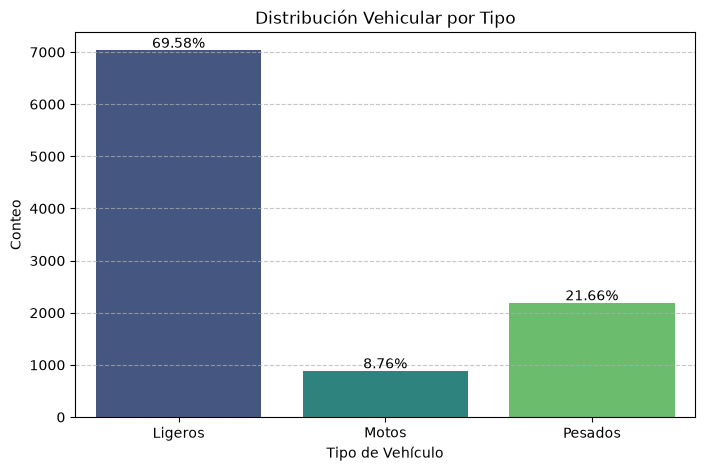

In [10]:
plt.figure(figsize=(8, 5))
sns.barplot(x='Tipo_Vehiculo', y='Conteo', data=df_distribucion, hue='Tipo_Vehiculo', palette='viridis', legend=False)
plt.title('Distribución Vehicular por Tipo')
plt.xlabel('Tipo de Vehículo')
plt.ylabel('Conteo')
for i, row in df_distribucion.iterrows():
    plt.text(i, row['Conteo'] + 50, f"{row['Porcentaje']:.2f}%", ha='center')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

In [11]:
display(df_distribucion.style.format({'Porcentaje': '{:.2f}%'}))

,Tipo_Vehiculo,Conteo,Porcentaje
0,Ligeros,7032,69.58%
1,Motos,885,8.76%
2,Pesados,2189,21.66%


## Estadisticas Descriptivas

Resumen estadistico de las tasas de flujo vehicular calculadas.

Metricas:
- Media, desviacion estandar, minimo, maximo
- Unidades: veh/s, veh/min, veh/h

## Estadísticas Descriptivas del Flujo

In [ ]:
resumen = pd.DataFrame({
    'Métrica': ['Flujo promedio', 'Desviación estándar', 'Mínimo', 'Máximo'],
    'veh/s': [df['Flujo_veh_seg'].mean(), df['Flujo_veh_seg'].std(), df['Flujo_veh_seg'].min(), df['Flujo_veh_seg'].max()],
    'veh/min': [df['Flujo_veh_min'].mean(), df['Flujo_veh_min'].std(), df['Flujo_veh_min'].min(), df['Flujo_veh_min'].max()],
    'veh/h': [df['Tasa_Flujo_veh_h'].mean(), df['Tasa_Flujo_veh_h'].std(), df['Tasa_Flujo_veh_h'].min(), df['Tasa_Flujo_veh_h'].max()]
})

resumen.style.format({'veh/s': '{:.3f}', 'veh/min': '{:.2f}', 'veh/h': '{:.1f}'})

## Visualización del Flujo Vehicular

In [ ]:
plt.figure(figsize=(10, 5))
sns.barplot(x='Muestra_Video', y='Flujo_veh_min', data=df, hue='Muestra_Video', palette='viridis', legend=False)
plt.axhline(df['Flujo_veh_min'].mean(), color='red', linestyle='--', label=f'Media = {df["Flujo_veh_min"].mean():.2f} veh/min')
plt.title('Flujo Vehicular por Muestra de Análisis')
plt.xlabel('Muestra de Análisis (Video)')
plt.ylabel('Tasa de Flujo (veh/min)')
plt.ylim(10, 25)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

In [ ]:
df.style.format({
    'Flujo_veh_seg': '{:.3f}',
    'Flujo_veh_min': '{:.2f}',
    'Tasa_Flujo_veh_h': '{:.1f}'
})
display(df)